# 7. Association Rules and Campaigns — Part B
## Pair-rule discovery and descriptive holdout checks

Run Part A and use its exported `assigned_baskets_clean.csv` and accepted mapping. This continuation does not modify Part A or assign pending customers.

Start with singleton -> singleton rules. Exact pair counting gives the same pair supports as exhaustive presence-based pair enumeration; it is not an Apriori implementation. Longer itemsets are deliberately deferred. No extra mlxtend dependency is needed for this version.

Discover rules on approximately 80% of customers within each segment. All baskets of a customer stay on one side. Score the fixed discovered rules on the remaining customers. This is a conditional basket-pattern robustness check with fixed segmentation, not independent validation of the segmentation, temporal forecasting, a significance test, or causal evidence.

Dependencies: numpy, pandas, matplotlib. Product mapping contains name-based conventions and two `other` fallbacks; exclude `other` tokens while retaining every eligible basket in category denominators.

### Revision notes
This revision keeps the original discovery thresholds and split seed. The existing holdout has already been inspected; it is a descriptive robustness sample, not a fresh untouched test set. No filters are retuned to improve its results. Reciprocal rules remain in full exports but are deduplicated for plots and campaign review. Statistical persistence is distinct from segment specificity and commercial suitability.

In [12]:
from pathlib import Path
import sys
import json
import importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent
sys.path.insert(0, str(project_root))
from utils.association_rule_mining_functions import (
    mine_segment_pairs, compare_rules, plot_top_pair_rules,
)

input_dir = project_root / "data" / "basket_analysis"
table_dir = project_root / "reports" / "tables" / "association_rules" / "part_b"
figure_dir = project_root / "reports" / "figures" / "association_rules" / "part_b"
for directory in [table_dir, figure_dir]:
    directory.mkdir(parents=True, exist_ok=True)

## 1. Load the audited baskets
The item export is JSON. Basket names remain distinct; for example oil and cooking oil are not merged. Unique products and categories represent presence, not units purchased.

In [13]:
data = pd.read_csv(input_dir / "assigned_baskets_clean.csv")
data["items"] = data["items"].apply(json.loads)
assert data["invoice_id"].notna().all() and data["invoice_id"].is_unique
assert data["customer_id"].notna().all()
assert data["cluster"].notna().all() and data["cluster"].mod(1).eq(0).all()
data["cluster"] = data["cluster"].astype(int)
assert data.groupby("customer_id")["cluster"].nunique().eq(1).all()
assert data["items"].map(lambda x: isinstance(x, list) and all(isinstance(v, str) for v in x)).all()
assert data["items"].str.len().gt(0).all()

display(data.groupby(["cluster", "segment_name"]).agg(
    baskets=("invoice_id", "size"), customers=("customer_id", "nunique")
))
print(f"Audited input: {len(data):,} baskets; {data['customer_id'].nunique():,} customers")

,,baskets,customers
cluster,segment_name,,
0,Established Multi-Category Shoppers,32012,8033
1,Electronics and Gaming Shoppers,10084,2560
2,"Low-Spending, Promotion-Oriented Shoppers",15470,3887
3,Promotion-Heavy Regular Shoppers,14940,3737
4,High-Spending Multi-Category Shoppers,12856,3284
5,Vegetable-Focused Shoppers,12885,3213


Audited input: 98,247 baskets; 24,714 customers


## 2. Build category baskets and report usable coverage
Accepted does not mean supplier-verified. Unknown products stop execution; no automatic guessed mapping is introduced. Excluding fallback tokens does not remove basket rows.

In [14]:
mapping = pd.read_csv(input_dir / "product_category_mapping.csv").fillna("")
assert mapping["product_name"].is_unique
allowed = {"groceries", "electronics", "vegetables", "nonalcohol_drinks", "alcohol_drinks",
           "meat", "fish", "hygiene", "petfood", "videogames", "other"}
accepted = mapping["review_status"].eq("reviewed") & mapping["category"].isin(allowed)
lookup = mapping.loc[accepted].set_index("product_name")["category"].to_dict()
vocabulary = {p for basket in data["items"] for p in basket}
assert vocabulary.issubset(lookup), "Review unaccepted or missing products before mining."

data["category_items"] = data["items"].apply(
    lambda basket: sorted({lookup[p] for p in basket if lookup[p] != "other"})
)
occurrences = sum(len(set(basket)) for basket in data["items"])
usable = sum(lookup[p] != "other" for basket in data["items"] for p in set(basket))
print(f"Meaningful-category product occurrences: {usable:,}/{occurrences:,} ({usable/occurrences:.2%})")
print("Empty category baskets retained:", data["category_items"].str.len().eq(0).sum())

Meaningful-category product occurrences: 877,642/883,666 (99.32%)
Empty category baskets retained: 0


## 3. Split by customer within segment
The split is fixed before rule discovery. No customer contributes baskets to both discovery and holdout. Holdout customers were part of the earlier clustering population, so this tests conditional rule consistency only.

Do not keep changing the seed or thresholds until holdout results look attractive. If holdout results guide new mining settings, describe that sample as validation and reserve a new untouched evaluation sample for later claims.

In [15]:
SPLIT_SEED = 42
HOLDOUT_FRACTION = .20
split_path = table_dir / "customer_discovery_holdout_split.csv"
expected_customers = data[["customer_id", "cluster"]].drop_duplicates()
if split_path.exists():
    customer_split = pd.read_csv(split_path)
    assert customer_split["customer_id"].is_unique
    assert customer_split["split"].isin(["discovery", "holdout"]).all()
    assert set(map(tuple, customer_split[["customer_id", "cluster"]].to_numpy())) == set(
        map(tuple, expected_customers.to_numpy())
    ), "Population changed: investigate instead of silently creating a different holdout."
    print("Reusing saved customer split.")
else:
    rng = np.random.default_rng(SPLIT_SEED)
    customer_split = expected_customers.sort_values(["cluster", "customer_id"]).copy()
    customer_split["split"] = "discovery"
    for cluster, group in customer_split.groupby("cluster"):
        assert len(group) >= 2
        n_holdout = min(len(group)-1, max(1, int(round(len(group)*HOLDOUT_FRACTION))))
        selected = rng.choice(group.index.to_numpy(), n_holdout, replace=False)
        customer_split.loc[selected, "split"] = "holdout"

data = data.merge(customer_split, on=["customer_id", "cluster"], validate="many_to_one")
discovery = data.loc[data["split"].eq("discovery")].copy()
holdout = data.loc[data["split"].eq("holdout")].copy()
assert set(discovery["customer_id"]).isdisjoint(holdout["customer_id"])
assert len(discovery) + len(holdout) == len(data)
split_summary = data.groupby(["cluster", "segment_name", "split"]).agg(
    baskets=("invoice_id", "size"), customers=("customer_id", "nunique")
)
display(split_summary)
customer_split.to_csv(table_dir / "customer_discovery_holdout_split.csv", index=False)

Reusing saved customer split.


baskets  \
cluster segment_name                              split                
0       Established Multi-Category Shoppers       discovery    25421   
                                                  holdout       6591   
1       Electronics and Gaming Shoppers           discovery     8103   
                                                  holdout       1981   
2       Low-Spending, Promotion-Oriented Shoppers discovery    12370   
                                                  holdout       3100   
3       Promotion-Heavy Regular Shoppers          discovery    11956   
                                                  holdout       2984   
4       High-Spending Multi-Category Shoppers     discovery    10323   
                                                  holdout       2533   
5       Vegetable-Focused Shoppers                discovery    10289   
                                                  holdout       2596   

                                                             customers  
cluster segment_name                              split                 
0       Established Multi-Category Shoppers       discovery       6426  
                                                  holdout         1607  
1       Electronics and Gaming Shoppers           discovery       2048  
                                                  holdout          512  
2       Low-Spending, Promotion-Oriented Shoppers discovery       3110  
                                                  holdout          777  
3       Promotion-Heavy Regular Shoppers          discovery       2990  
                                                  holdout          747  
4       High-Spending Multi-Category Shoppers     discovery       2627  
                                                  holdout          657  
5       Vegetable-Focused Shoppers                discovery       2570  
                                                  holdout          643

## 4. Predeclare exploratory discovery filters
These are screening settings, not statistical significance thresholds or proof of commercial value. The same settings are applied across segments; occurrence counts and rates are reported together. We deliberately do not force at least one rule per segment.

- Joint occurrence: at least 30 discovery baskets AND support of at least 0.5%.
- Confidence: at least 20%.
- Lift: at least 1.10.

Category pairs may be ubiquitous and show little lift; it is acceptable if none pass. Both A -> B and B -> A may appear: they share support/lift but can have different confidence.

In [16]:
THRESHOLDS = {
    "min_count": 30,
    "min_support": .005,
    "min_confidence": .20,
    "min_lift": 1.10,
}
all_results = []
for level, column in [("item", "items"), ("category", "category_items")]:
    discovered, _ = mine_segment_pairs(discovery, column, level, THRESHOLDS)
    evaluated = compare_rules(discovered, holdout, discovery, column)
    all_results.append(evaluated)

rules = pd.concat(all_results, ignore_index=True)
rules["segment_name"] = rules["cluster"].map(data.groupby("cluster")["segment_name"].first())
rules["rule"] = rules["antecedent"] + " -> " + rules["consequent"]
# Descriptive holdout support flag; not a significance or campaign-success test.
rules["holdout_minimum_evidence_check"] = (
    rules["holdout_joint_count"].ge(10)
    & rules["holdout_antecedent_count"].ge(20)
    & rules["holdout_lift"].gt(1)
)
print(f"Discovered directed rules: {len(rules):,}")

# Descriptive flags only: no significance, targeting, or causal conclusion.
rules["higher_confidence_than_rest"] = rules["confidence_difference_vs_rest"].gt(0)
rules["higher_lift_than_rest"] = rules["lift_difference_vs_rest"].gt(0)
rules["holdout_lift_change"] = rules["holdout_lift"] - rules["lift"]
rules["holdout_confidence_change"] = rules["holdout_confidence"] - rules["confidence"]
rules["discovery_baskets_per_supporting_customer"] = (
    rules["joint_count"] / rules["joint_customers"].replace(0, np.nan)
)
rules["pair_key"] = rules.apply(
    lambda row: " | ".join(sorted([row["antecedent"], row["consequent"]])), axis=1
)

# First choose one direction within each pair.
# Direction depends on discovery confidence, not floating-point lift ties.
unique_pairs = (
    rules
    .sort_values(
        [
            "cluster",
            "level",
            "pair_key",
            "confidence",
            "antecedent",
        ],
        ascending=[True, True, True, False, True],
    )
    .drop_duplicates(["cluster", "level", "pair_key"])
    .sort_values(
        ["cluster", "level", "lift", "joint_count"],
        ascending=[True, True, False, False],
    )
    .copy()
)

assert not unique_pairs.duplicated(
    ["cluster", "level", "pair_key"]
).any()


Discovered directed rules: 2,803


## 5. Inspect rules and their denominators
Support = joint baskets / all baskets in the segment split. Confidence = joint / antecedent baskets. Lift = confidence / consequent prevalence. Leverage = support minus the product of marginal prevalences. A rule can have high confidence merely because the consequent is common.

`rest_` metrics use discovery baskets belonging to all OTHER assigned segments. Differences are descriptive; they are not incremental campaign lift or causal effects. Undefined metrics remain missing when denominators are zero.

`holdout_minimum_evidence_check` means only joint baskets >=10, antecedent baskets >=20, and lift >1. A value near 1 may pass but still offer little association. `higher_confidence_than_rest` and `higher_lift_than_rest` answer different questions; neither establishes causality or statistical significance. Discovery-rest comparisons can also reflect differences in customer/basket composition.

In [17]:
count_index = pd.MultiIndex.from_product(
    [sorted(data["cluster"].unique()), ["item", "category"]], names=["cluster", "level"]
)
rule_counts = rules.groupby(["cluster", "level"]).size().reindex(count_index, fill_value=0).rename("discovered_rules")
display(rule_counts.to_frame())

view_columns = [
    "rule", "joint_count", "joint_customers", "support", "confidence", "consequent_support",
    "lift", "leverage", "rest_joint_count", "rest_confidence", "rest_lift",
    "confidence_difference_vs_rest", "higher_confidence_than_rest", "higher_lift_than_rest", "holdout_joint_count", "holdout_joint_customers",
    "holdout_confidence", "holdout_lift", "holdout_minimum_evidence_check",
]
for (cluster, level), group in rules.groupby(["cluster", "level"]):
    print(f"Cluster {cluster} — {level} rules (discovery-ranked; not a final recommendation)")
    display(group.sort_values(["lift", "joint_count"], ascending=False)[view_columns].head(10).round(3))

discovered_rules
cluster level                     
0       item                   616
        category                15
1       item                   422
        category                13
2       item                   363
        category                 8
3       item                   556
        category                12
4       item                   605
        category                13
5       item                   178
        category                 2

Cluster 0 — category rules (discovery-ranked; not a final recommendation)


,rule,joint_count,joint_customers,support,confidence,consequent_support,lift,leverage,rest_joint_count,rest_confidence,rest_lift,confidence_difference_vs_rest,higher_confidence_than_rest,higher_lift_than_rest,holdout_joint_count,holdout_joint_customers,holdout_confidence,holdout_lift,holdout_minimum_evidence_check
2740,alcohol_drinks -> electronics,5706,2288,0.224,0.605,0.391,1.548,0.079,9240,0.571,1.493,0.034,True,True,1542,607,0.616,1.532,True
2741,electronics -> alcohol_drinks,5706,2288,0.224,0.574,0.371,1.548,0.079,9240,0.455,1.493,0.118,True,True,1542,607,0.582,1.532,True
2742,alcohol_drinks -> fish,4891,2133,0.192,0.519,0.353,1.471,0.062,5764,0.356,1.416,0.163,True,True,1281,557,0.512,1.450,True
2743,fish -> alcohol_drinks,4891,2133,0.192,0.545,0.371,1.471,0.062,5764,0.432,1.416,0.113,True,True,1281,557,0.550,1.450,True
2744,electronics -> fish,4878,2321,0.192,0.491,0.353,1.391,0.054,6680,0.329,1.309,0.161,True,True,1284,624,0.484,1.372,True
2745,fish -> electronics,4878,2321,0.192,0.544,0.391,1.391,0.054,6680,0.500,1.309,0.043,True,True,1284,624,0.552,1.372,True
2746,petfood -> videogames,3517,2052,0.138,0.781,0.586,1.333,0.035,3153,0.538,1.154,0.244,True,True,903,517,0.772,1.324,True
2747,videogames -> petfood,3517,2052,0.138,0.236,0.177,1.333,0.035,3153,0.128,1.154,0.108,True,True,903,517,0.235,1.324,True
2748,fish -> nonalcohol_drinks,4710,2572,0.185,0.525,0.442,1.188,0.029,7341,0.550,1.048,-0.025,False,True,1224,686,0.526,1.155,True
2749,nonalcohol_drinks -> fish,4710,2572,0.185,0.419,0.353,1.188,0.029,7341,0.264,1.048,0.155,True,True,1224,686,0.408,1.155,True


Cluster 0 — item rules (discovery-ranked; not a final recommendation)


,rule,joint_count,joint_customers,support,confidence,consequent_support,lift,leverage,rest_joint_count,rest_confidence,rest_lift,confidence_difference_vs_rest,higher_confidence_than_rest,higher_lift_than_rest,holdout_joint_count,holdout_joint_customers,holdout_confidence,holdout_lift,holdout_minimum_evidence_check
0,white wine -> cider,672,305,0.026,0.406,0.052,7.785,0.023,2042,0.436,6.409,-0.030,False,True,169,78,0.399,8.009,True
1,cider -> white wine,672,305,0.026,0.507,0.065,7.785,0.023,2042,0.566,6.409,-0.059,False,True,169,78,0.515,8.009,True
2,white wine -> dessert wine,521,280,0.020,0.315,0.045,7.022,0.018,1581,0.338,5.753,-0.023,False,True,126,69,0.297,7.122,True
3,dessert wine -> white wine,521,280,0.020,0.457,0.065,7.022,0.018,1581,0.508,5.753,-0.051,False,True,126,69,0.458,7.122,True
4,beer -> white wine,528,288,0.021,0.415,0.065,6.372,0.018,1659,0.472,5.343,-0.057,False,True,123,65,0.394,6.128,True
5,white wine -> beer,528,288,0.021,0.319,0.050,6.372,0.018,1659,0.354,5.343,-0.035,False,True,123,65,0.290,6.128,True
6,cider -> dessert wine,365,221,0.014,0.275,0.045,6.148,0.012,1156,0.320,5.461,-0.045,False,True,101,57,0.308,7.380,True
7,dessert wine -> cider,365,221,0.014,0.320,0.052,6.148,0.012,1156,0.371,5.461,-0.051,False,True,101,57,0.367,7.380,True
8,cider -> beer,386,243,0.015,0.291,0.050,5.822,0.013,1141,0.316,4.771,-0.025,False,True,86,57,0.262,5.539,True
9,beer -> cider,386,243,0.015,0.303,0.052,5.822,0.013,1141,0.325,4.771,-0.021,False,True,86,57,0.276,5.539,True


Cluster 1 — category rules (discovery-ranked; not a final recommendation)


... (15 outputs left out)

Cluster 5 — category rules (discovery-ranked; not a final recommendation)


,rule,joint_count,joint_customers,support,confidence,consequent_support,lift,leverage,rest_joint_count,rest_confidence,rest_lift,confidence_difference_vs_rest,higher_confidence_than_rest,higher_lift_than_rest,holdout_joint_count,holdout_joint_customers,holdout_confidence,holdout_lift,holdout_minimum_evidence_check
2801,alcohol_drinks -> videogames,678,564,0.066,0.509,0.456,1.116,0.007,12007,0.495,0.966,0.014,True,True,149,134,0.460,1.025,True
2802,petfood -> videogames,362,322,0.035,0.507,0.456,1.112,0.004,6308,0.654,1.276,-0.147,False,False,86,74,0.462,1.030,True


Cluster 5 — item rules (discovery-ranked; not a final recommendation)


,rule,joint_count,joint_customers,support,confidence,consequent_support,lift,leverage,rest_joint_count,rest_confidence,rest_lift,confidence_difference_vs_rest,higher_confidence_than_rest,higher_lift_than_rest,holdout_joint_count,holdout_joint_customers,holdout_confidence,holdout_lift,holdout_minimum_evidence_check
2562,final fantasy xx -> green beans,79,77,0.008,0.269,0.179,1.504,0.003,50,0.030,1.091,0.239,True,True,15,15,0.254,1.398,True
2563,chocolate bread -> zucchini,69,68,0.007,0.229,0.168,1.365,0.002,32,0.017,0.577,0.212,True,True,10,10,0.149,0.910,False
2564,mineral water -> cauliflower,108,104,0.010,0.269,0.200,1.346,0.003,113,0.029,1.069,0.241,True,True,17,17,0.183,0.934,False
2565,strong cheese -> frozen vegetables,56,55,0.005,0.299,0.226,1.322,0.001,141,0.037,0.924,0.263,True,True,15,14,0.319,1.549,True
2566,low fat yogurt -> green beans,67,67,0.007,0.233,0.179,1.302,0.002,40,0.022,0.805,0.211,True,True,9,9,0.134,0.739,False
2567,metroid fusion -> green beans,83,80,0.008,0.231,0.179,1.291,0.002,62,0.027,1.004,0.203,True,True,17,16,0.189,1.039,True
2568,mint green tea -> frozen vegetables,151,143,0.015,0.289,0.226,1.275,0.003,228,0.078,1.981,0.210,True,False,27,27,0.205,0.993,False
2569,extra dark chocolate -> frozen vegetables,58,57,0.006,0.289,0.226,1.274,0.001,57,0.043,1.076,0.246,True,True,9,9,0.265,1.284,False
2570,chili -> zucchini,56,56,0.005,0.214,0.168,1.273,0.001,44,0.028,0.950,0.186,True,True,10,10,0.189,1.150,True
2571,green grapes -> zucchini,198,190,0.019,0.212,0.168,1.264,0.004,74,0.034,1.149,0.178,True,True,42,42,0.193,1.174,True


### Holdout and unique-pair summary
Report successes and failures together. Passing percentages concern rules selected in discovery, not all possible pairs or all customers. Weak positive holdout associations remain visible instead of being reclassified as commercially strong.

In [18]:
holdout_summary = rules.groupby(["cluster", "level"]).agg(
    discovered_directed_rules=("rule", "size"),
    passing_minimum_check=("holdout_minimum_evidence_check", "sum"),
    median_discovery_lift=("lift", "median"),
    median_holdout_lift=("holdout_lift", "median"),
    defined_holdout_lifts=("holdout_lift", "count"),
)
holdout_summary = holdout_summary.reindex(count_index)
for column in ["discovered_directed_rules", "passing_minimum_check", "defined_holdout_lifts"]:
    holdout_summary[column] = holdout_summary[column].fillna(0).astype(int)
holdout_summary["passing_pct"] = (
    holdout_summary["passing_minimum_check"]
    / holdout_summary["discovered_directed_rules"].replace(0, np.nan) * 100
)
holdout_summary["unique_pairs"] = unique_pairs.groupby(["cluster", "level"]).size().reindex(count_index, fill_value=0)
display(holdout_summary.round(3))

# No numerical weakness threshold is invented after looking at the holdout.
# Inspect exact lift and confidence changes, rather than treating True as approval.
weakening_examples = rules.sort_values("holdout_lift_change").head(15)
display(weakening_examples[["cluster", "level", "rule", "joint_count", "holdout_joint_count",
    "lift", "holdout_lift", "holdout_lift_change", "confidence", "holdout_confidence",
    "holdout_minimum_evidence_check"]].round(3))

discovered_directed_rules  passing_minimum_check  \
cluster level                                                        
0       item                            616                    602   
        category                         15                     15   
1       item                            422                    380   
        category                         13                     13   
2       item                            363                    296   
        category                          8                      8   
3       item                            556                    496   
        category                         12                     12   
4       item                            605                    575   
        category                         13                     13   
5       item                            178                    118   
        category                          2                      2   

                  median_discovery_lift  median_holdout_lift  \
cluster level                                                  
0       item                      1.684                1.692   
        category                  1.333                1.324   
1       item                      1.337                1.333   
        category                  1.169                1.139   
2       item                      1.161                1.123   
        category                  1.175                1.225   
3       item                      1.389                1.385   
        category                  1.130                1.125   
4       item                      1.953                1.890   
        category                  1.291                1.264   
5       item                      1.144                1.042   
        category                  1.114                1.028   

                  defined_holdout_lifts  passing_pct  unique_pairs  
cluster level                                                       
0       item                        616       97.727           552  
        category                     15      100.000             8  
1       item                        422       90.047           369  
        category                     13      100.000             8  
2       item                        363       81.543           336  
        category                      8      100.000             5  
3       item                        556       89.209           511  
        category                     12      100.000             6  
4       item                        605       95.041           535  
        category                     13      100.000             8  
5       item                        178       66.292           176  
        category                      2      100.000             2

,cluster,level,rule,joint_count,holdout_joint_count,lift,holdout_lift,holdout_lift_change,confidence,holdout_confidence,holdout_minimum_evidence_check
1041,2,item,champagne -> white wine,72,8,6.063,2.902,-3.162,0.209,0.104,False
617,1,item,cologne -> oil,77,12,4.751,3.175,-1.577,0.314,0.231,True
18,0,item,bramble -> beer,197,32,4.243,2.770,-1.472,0.212,0.131,True
637,1,item,spaghetti -> fresh tuna,152,19,3.686,2.233,-1.453,0.335,0.179,True
636,1,item,fresh tuna -> spaghetti,152,19,3.686,2.233,-1.453,0.207,0.119,True
1058,2,item,ratchet & clank -> babies food,94,6,2.381,0.956,-1.425,0.245,0.094,False
16,0,item,red wine -> cider,204,34,4.473,3.148,-1.325,0.233,0.157,True
694,1,item,gluten free bar -> fresh tuna,45,4,2.222,0.923,-1.299,0.202,0.074,False
2020,4,item,metroid prime -> energy drink,82,13,3.296,2.028,-1.268,0.248,0.162,True
2057,4,item,green grapes -> barbecue sauce,64,8,2.694,1.462,-1.232,0.205,0.121,False


## 6. Unique-pair plots
Show one direction per underlying item pair so reciprocal rules do not occupy multiple slots. Ranking uses discovery lift; direction uses discovery confidence. These are descriptive rankings, not optimized recommendations. Holdout metrics remain in the full tables.

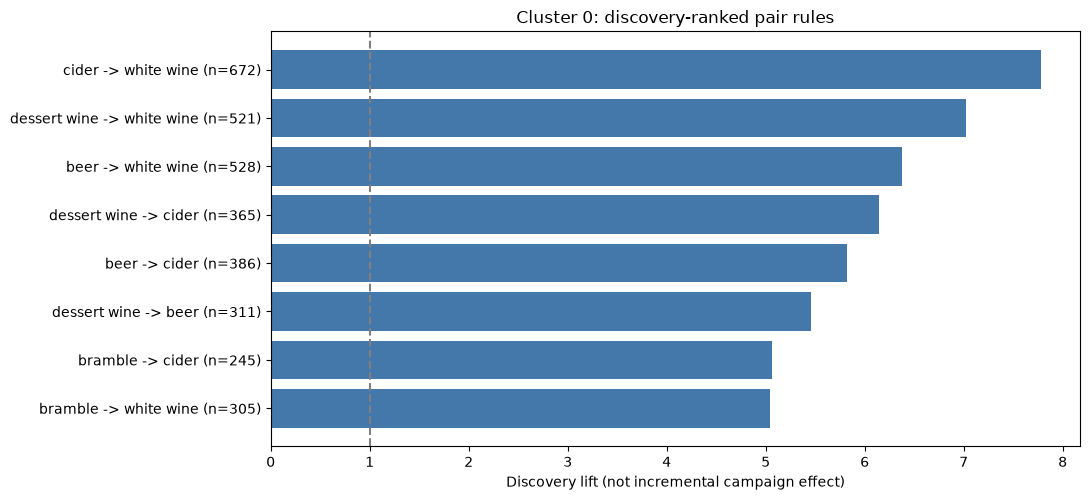

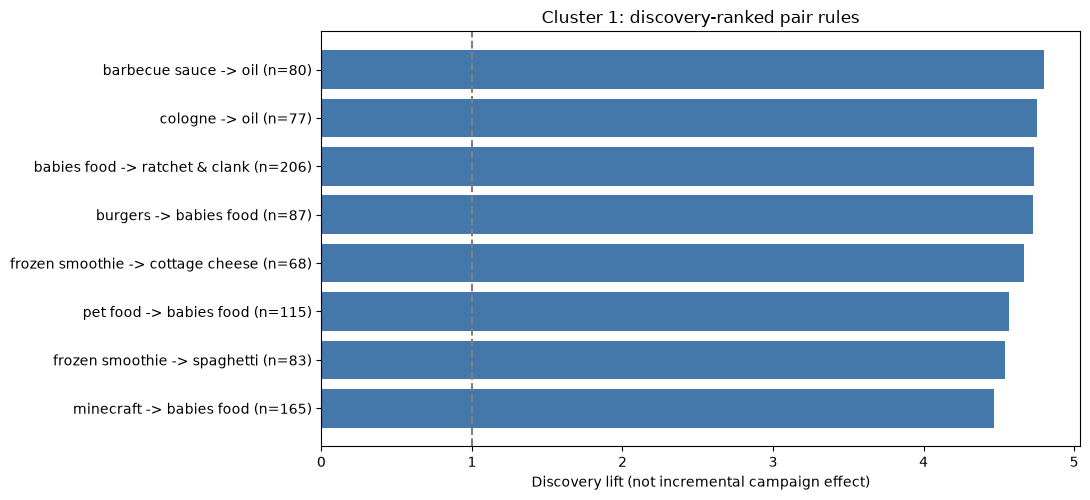

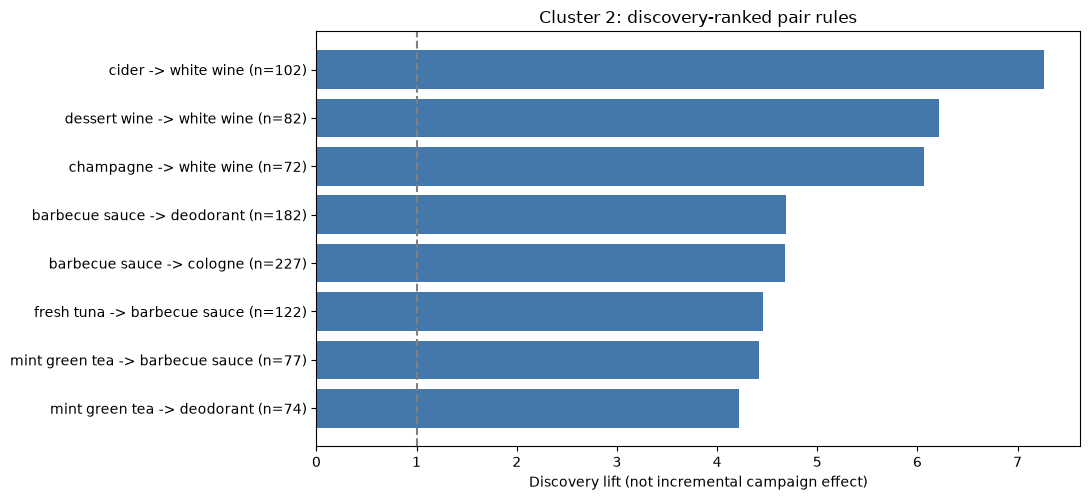

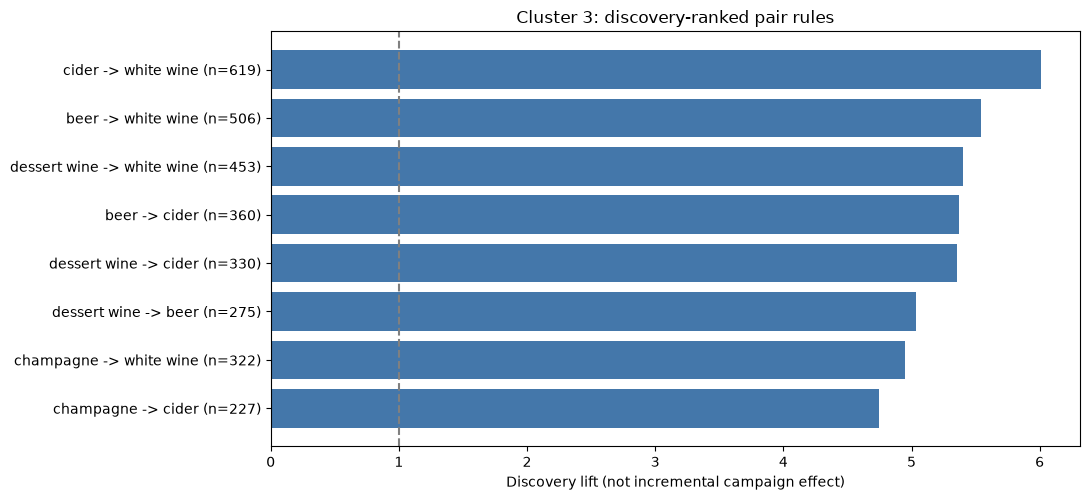

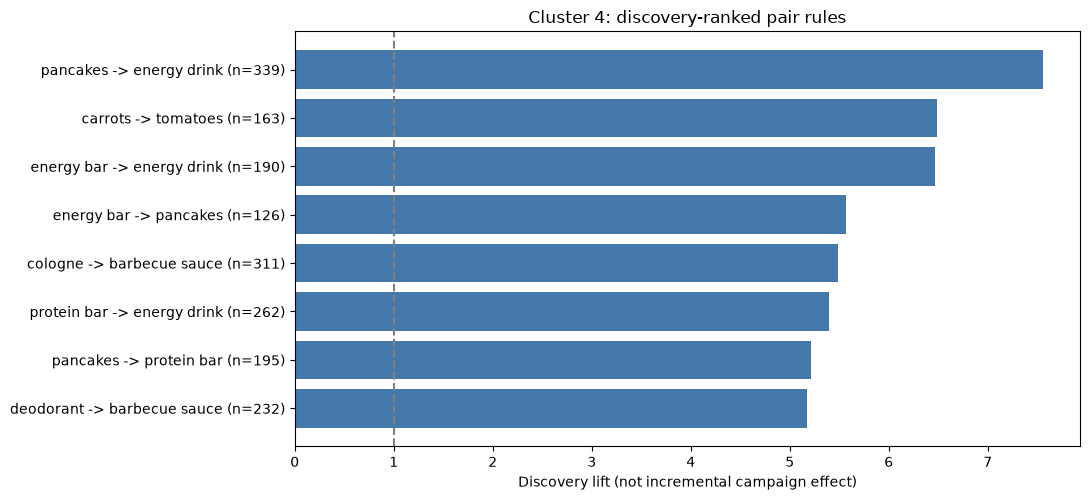

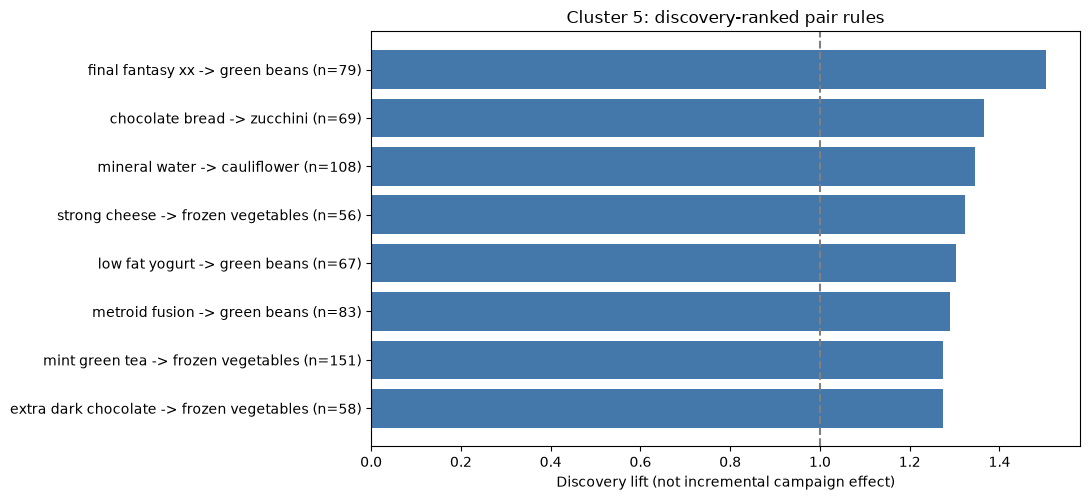

In [19]:
for cluster in sorted(data["cluster"].unique()):
    fig = plot_top_pair_rules(unique_pairs.loc[unique_pairs["level"].eq("item")], cluster, top_n=8)
    fig.savefig(figure_dir / f"cluster_{cluster}_item_rules.png", dpi=160, bbox_inches="tight")
    plt.show()

## 7. Campaign-evidence worksheet
Select up to five unique discovery-ranked item pairs per segment. Do not filter by holdout results or require an attractive rule in every segment. The retained direction is provisional; review exposure, consequent prevalence, counts, outside-segment comparisons, and actual product compatibility before deciding an offer.

All rows begin as pending commercial review. A high-lift rule such as a videogame paired with food is an observed association, not evidence of a particular persona or a persuasive bundle. Promotions involving regulated products require applicable eligibility and policy review. No discount or success claim is generated automatically.

In [20]:
worksheet = (
    unique_pairs.loc[unique_pairs["level"].eq("item")]
    .sort_values(["cluster", "lift", "joint_count"], ascending=[True, False, False])
    .groupby("cluster", group_keys=False).head(5).copy()
)
worksheet["statistical_note"] = np.where(
    worksheet["holdout_minimum_evidence_check"],
    "Minimum descriptive holdout evidence met; commercial value unestablished",
    "Minimum descriptive holdout evidence not met; retain as discovery finding only",
)
for column in ["campaign_hypothesis", "offer_mechanic", "commercial_constraints",
               "risk_of_discounting_existing_purchases", "randomized_test_plan", "success_metric"]:
    worksheet[column] = ""
worksheet["review_decision"] = "pending_commercial_review"

with pd.option_context("display.max_colwidth", 65, "display.max_columns", None):
    display(worksheet[["cluster", "segment_name"] + view_columns].round(3))
print("No worksheet row is automatically approved as a campaign.")


,cluster,segment_name,rule,joint_count,joint_customers,support,confidence,consequent_support,lift,leverage,rest_joint_count,rest_confidence,rest_lift,confidence_difference_vs_rest,higher_confidence_than_rest,higher_lift_than_rest,holdout_joint_count,holdout_joint_customers,holdout_confidence,holdout_lift,holdout_minimum_evidence_check
1,0,Established Multi-Category Shoppers,cider -> white wine,672,305,0.026,0.507,0.065,7.785,0.023,2042,0.566,6.409,-0.059,False,True,169,78,0.515,8.009,True
3,0,Established Multi-Category Shoppers,dessert wine -> white wine,521,280,0.020,0.457,0.065,7.022,0.018,1581,0.508,5.753,-0.051,False,True,126,69,0.458,7.122,True
4,0,Established Multi-Category Shoppers,beer -> white wine,528,288,0.021,0.415,0.065,6.372,0.018,1659,0.472,5.343,-0.057,False,True,123,65,0.394,6.128,True
7,0,Established Multi-Category Shoppers,dessert wine -> cider,365,221,0.014,0.320,0.052,6.148,0.012,1156,0.371,5.461,-0.051,False,True,101,57,0.367,7.380,True
9,0,Established Multi-Category Shoppers,beer -> cider,386,243,0.015,0.303,0.052,5.822,0.013,1141,0.325,4.771,-0.021,False,True,86,57,0.276,5.539,True
616,1,Electronics and Gaming Shoppers,barbecue sauce -> oil,80,42,0.010,0.317,0.066,4.799,0.008,6059,0.773,2.018,-0.455,False,True,19,10,0.365,5.027,True
617,1,Electronics and Gaming Shoppers,cologne -> oil,77,39,0.010,0.314,0.066,4.751,0.008,5258,0.651,1.700,-0.336,False,True,12,11,0.231,3.175,True
618,1,Electronics and Gaming Shoppers,babies food -> ratchet & clank,206,85,0.025,0.363,0.077,4.733,0.020,6298,0.461,3.606,-0.098,False,True,66,26,0.426,5.143,True
620,1,Electronics and Gaming Shoppers,burgers -> babies food,87,61,0.011,0.331,0.070,4.727,0.008,2628,0.459,2.366,-0.128,False,True,25,16,0.410,5.238,True
621,1,Electronics and Gaming Shoppers,frozen smoothie -> cottage cheese,68,48,0.008,0.209,0.045,4.669,0.007,773,0.184,2.861,0.025,True,True,15,12,0.170,3.481,True


No worksheet row is automatically approved as a campaign.


## 8. Export and record settings
All passing discovery rules are exported, including those with weak or undefined holdout evidence. Retain failures rather than reporting only attractive results.

In [21]:
rules.to_csv(table_dir / "pair_rules_discovery_with_checks.csv", index=False)
rule_counts.to_csv(table_dir / "pair_rule_counts.csv")
split_summary.to_csv(table_dir / "rule_split_summary.csv")
worksheet.to_csv(table_dir / "campaign_evidence_worksheet.csv", index=False)
settings = {
    "algorithm": "exact presence-based singleton-pair counting; not Apriori",
    "scope": "assigned, audited transaction baskets from Part A",
    "discovery_thresholds": THRESHOLDS,
    "customer_split_seed": SPLIT_SEED, "holdout_fraction_customers": HOLDOUT_FRACTION,
    "excluded_category_token": "other", "empty_category_baskets_retained": True,
    "rest_reference": "all other assigned segments, discovery split only",
    "holdout_check": "joint baskets >=10, antecedent baskets >=20, lift >1; descriptive only",
    "mapping_assumptions": mapping.loc[mapping["category"].eq("other"), "product_name"].tolist(),
    "input_baskets": len(data), "input_customers": int(data["customer_id"].nunique()),
    "numpy_version": importlib.metadata.version("numpy"),
    "pandas_version": importlib.metadata.version("pandas"),
}
(table_dir / "pair_rule_settings.json").write_text(json.dumps(settings, indent=2))
mapping.to_csv(table_dir / "mapping_snapshot.csv", index=False)
print("Part B exported. Inspect evidence before completing campaign recommendations.")
unique_pairs.to_csv(table_dir / "unique_pair_review.csv", index=False)
holdout_summary.to_csv(table_dir / "holdout_evidence_summary.csv")
weakening_examples.to_csv(table_dir / "holdout_weakening_examples.csv", index=False)
settings.update({
    "revision": "evidence_review_v2",
    "holdout_status": "Previously inspected descriptive robustness sample; not a new untouched test",
    "review_deduplication": "One direction per cluster/level/unordered pair; direction by discovery confidence",
    "campaign_ranking": "Discovery lift then joint count; no holdout tuning or automatic approval",
    "holdout_flag_name": "holdout_minimum_evidence_check",
})
(table_dir / "pair_rule_settings.json").write_text(json.dumps(settings, indent=2))


Part B exported. Inspect evidence before completing campaign recommendations.


1160

In [22]:
print(f"Eligible baskets analyzed: {len(data):,}")
print(f"Customers represented: {data['customer_id'].nunique():,}")
print(f"Directed discovery rules: {len(rules):,}")
print(f"Unique segment-level/level pairs: {len(unique_pairs):,}")
print(f"Rules meeting minimum holdout evidence: {int(rules['holdout_minimum_evidence_check'].sum()):,}")
print("Commercially approved campaigns: none automatically generated.")

Eligible baskets analyzed: 98,247
Customers represented: 24,714
Directed discovery rules: 2,803
Unique segment-level/level pairs: 2,516
Rules meeting minimum holdout evidence: 2,530
Commercially approved campaigns: none automatically generated.


## 10. Interpretation and limitations
## Results Summary

The analysis covered 98,247 audited baskets from 24,714 assigned customers.
It identified 2,803 directed pair rules under the fixed discovery filters.

After removing reciprocal duplication for review, 2,516 unique
segment-and-level pairs remained. A total of 2,530 directed rules met
the minimum descriptive holdout check; this is not a significance test
or evidence of campaign effectiveness.

Item-rule persistence varied across segments. The vegetable-focused
segment showed the weakest overall holdout results, with 66.29% meeting
the minimum check and median holdout lift of 1.042.

High lift did not consistently imply greater confidence than in the rest
of the population. Campaign selection therefore requires review of
counts, outside-segment comparisons, holdout behavior, and commercial
plausibility.

No campaigns were approved automatically. The next stage is to document
a small set of testable campaign hypotheses and retain unsuitable
associations as descriptive findings. 

The outputs distinguish discovered directed rules, unique co-occurring pairs, minimum descriptive holdout evidence, and outside-segment differences. None is an estimate of incremental sales. Pair direction indicates a conditional proportion, not purchase sequence.

The holdout has already been examined. Additional choices informed by it are exploratory/validation decisions; do not claim a new untouched test. A stronger later evaluation would use genuinely new customers or a prospective campaign experiment. Customer splitting limits within-customer overlap, but feature preparation and segmentation were fitted previously and remain fixed.

Repeated baskets per customer are not independent observations. Supporting-customer counts help interpretation but are not a statistical correction. No confidence intervals or multiple-testing guarantees are provided. High lift can coexist with lower confidence than the rest of the population. Differences in marginal prevalence and segment mixture matter.

The sampled baskets do not establish real shopping frequency or future preferences. Name-based mappings, annualized-spending assumptions, deferred customers, and ambiguous invoices limit scope. All empty usable-category baskets stay in category denominators.

Complete campaign hypotheses only where there is defensible commercial logic. Leave unsuitable findings as observed associations. Randomized tests should allocate at customer level, define an appropriate control, record margin and eligibility constraints, and predeclare success measures. Discount values remain unset without commercial evidence.